# Binary Relevance for Multilabel Classification

## Overview

This notebook implements **Binary Relevance**, a classical approach that transforms multiclass classification problems into multilabel classification. Starting from a dataset where each image has a single weather label (rain, snow, lightning, etc.), Binary Relevance enables the model to predict multiple weather phenomena simultaneously in a single image.

## What is Binary Relevance?

Binary Relevance decomposes a multilabel problem into multiple independent binary classification problems. For a dataset with N classes:

- **Train N binary classifiers** (one per class)
- Each classifier learns: "Does this image belong to class X?" (Yes/No)
- At inference time, run all N classifiers and combine their outputs
- Apply a threshold to determine which labels are active

### From Multiclass to Multilabel

Our original dataset is **multiclass**: each image has one label (e.g., "rain" OR "snow").

With Binary Relevance, we convert this into **multilabel** capability:
- Each binary expert asks: "Is this rain?" independently of other classes
- Multiple experts can respond "Yes" for the same image
- Result: Images can be classified as "rain + lightning" or "volcano + smoke"

This is particularly useful for weather phenomena that naturally co-occur in images.

## Architecture

### Transfer Learning with EfficientNetB0

Each binary expert uses the same architecture:

```
Input (224x224x3)
    ↓
EfficientNetB0 (frozen, pretrained on ImageNet)
    ↓
GlobalAveragePooling2D
    ↓
BatchNormalization
    ↓
Dense(256, relu) + L2 regularization
    ↓
Dropout(0.5)
    ↓
Dense(64, relu) + L2 regularization
    ↓
Dropout(0.3)
    ↓
Dense(1, sigmoid) + L2 regularization
    ↓
Binary Output: P(belongs to class X)
```

### Training Strategy

**Single Phase - Frozen Backbone:**
- EfficientNetB0 base: **Frozen** (weights from ImageNet)
- Custom head: **Trainable**
- Loss: Binary crossentropy
- Per expert: 6 epochs with ReduceLROnPlateau

**Benefits:**
- Fast training (only ~350K parameters per expert vs 4M+ if unfrozen)
- Leverages pretrained visual features
- Prevents overfitting on small dataset
- Each expert specializes independently

### Binary Dataset Construction

For each class expert (e.g., "rain"):
- **Positive samples** (label=1): All images from "rain" class
- **Negative samples** (label=0): Balanced sample from all other classes
- Balance ratio 1.0: equal number of positives and negatives

This prevents the binary classifier from being biased toward the negative class.

## Advantages of Binary Relevance

Simple and interpretable: one model per class  
Converts multiclass data to multilabel without requiring new annotations  
Each expert can be trained and tuned independently  
Flexible threshold control per class or globally  
Naturally handles class imbalance through sampling strategy  
Parallelizable inference: all experts run simultaneously

## Disadvantages

Ignores label correlations (each expert is independent)  
Requires training N separate models  
Higher inference cost (N forward passes)

## Expected Outcomes

By the end of this notebook:
- 12 binary expert models trained (one per weather class)
- Multilabel prediction system that can identify multiple weather phenomena
- Per-class evaluation metrics (precision, recall, F1)
- Visualization of multilabel predictions on test images

---


## Library Installation

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import  ReduceLROnPlateau
from tensorflow.keras import backend as K
from tensorflow.keras.applications.efficientnet import preprocess_input

# Configure GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✓ GPU memory growth enabled for {len(gpus)} GPU(s)")
    except RuntimeError as e:
        print(f"GPU configuration error: {e}")

import matplotlib.pyplot as plt
import seaborn as sns
import gc 
import random
import numpy as np
import os
import shutil
import pandas as pd


sns.set_style('whitegrid')
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

✓ GPU memory growth enabled for 1 GPU(s)
TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Path Configuration

In [2]:
# Proyect Path
MAIN_PATH = './Part-1'
# Base path of your dataset
BASE_PATH = MAIN_PATH + '/dataset'

if os.path.exists(BASE_PATH):
    print(f"✓ Path found: {BASE_PATH}")
    print(f"Available folders: {os.listdir(BASE_PATH)}")
else:
    print(f"✗ Path not found. Please adjust BASE_PATH")

✓ Path found: ./Part-1/dataset
Available folders: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow', 'volcanos']


## Hyperparameter Configuration

In [3]:
CONFIG = {
    'IMG_SIZE': (224, 224),
    'BATCH_SIZE': 16,
    'EPOCHS': 20,
    'LEARNING_RATE': 0.001,
    'VALIDATION_SPLIT': 0.2,
    'SEED': 42,
    'THRESHOLD': 0.7
}

np.random.seed(CONFIG['SEED'])
tf.random.set_seed(CONFIG['SEED'])

print("Model configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")

Model configuration:
  IMG_SIZE: (224, 224)
  BATCH_SIZE: 16
  EPOCHS: 20
  LEARNING_RATE: 0.001
  VALIDATION_SPLIT: 0.2
  SEED: 42
  THRESHOLD: 0.7


## Dataset Preparation and Exploration

✓ Balanced dataset already exists: ./Part-1/dataset_balanced


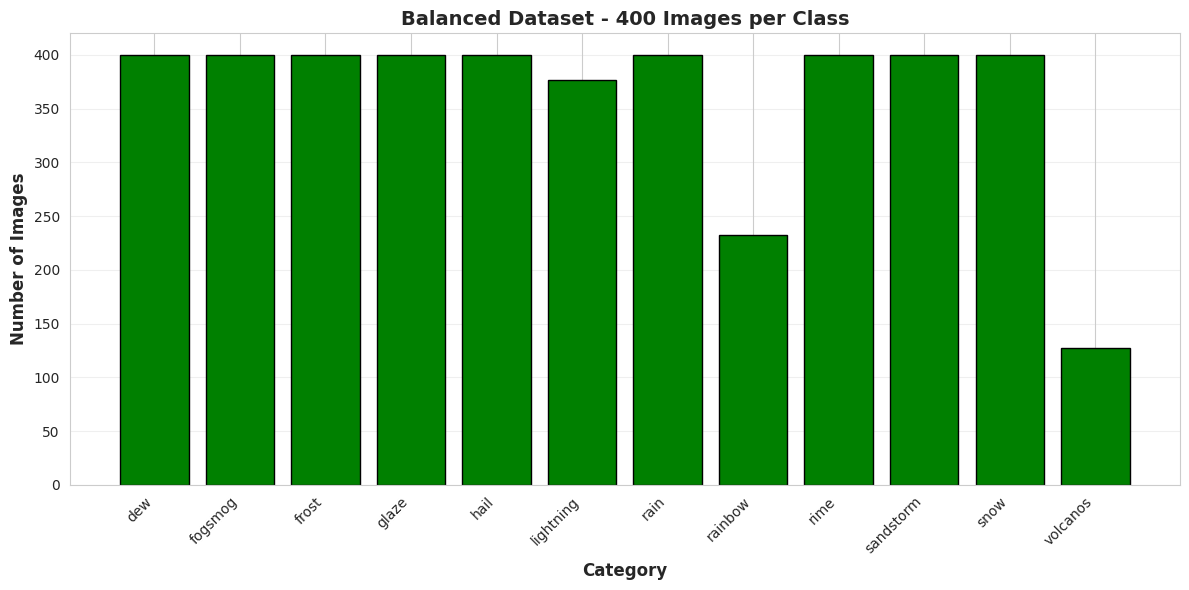

In [4]:
def create_balanced_dataset(base_path, max_samples_per_class=100):
    """
    Creates a balanced dataset by copying max X images per category.
    Balancing is crucial for binary relevance to prevent bias toward majority classes
    when creating binary (one-vs-rest) training sets.
    """

    balanced_path = base_path + "_balanced"

    if os.path.exists(balanced_path):
        print(f"✓ Balanced dataset already exists: {balanced_path}")
        return balanced_path

    os.makedirs(balanced_path)

    categories = [d for d in os.listdir(base_path)
                 if os.path.isdir(os.path.join(base_path, d))]

    for category in categories:
        category_path = os.path.join(base_path, category)
        balanced_category_path = os.path.join(balanced_path, category)
        os.makedirs(balanced_category_path, exist_ok=True)

        images = [f for f in os.listdir(category_path)
                 if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        if len(images) > max_samples_per_class:
            selected_images = np.random.choice(images, max_samples_per_class, replace=False)
        else:
            selected_images = images

        for img in selected_images:
            src = os.path.join(category_path, img)
            dst = os.path.join(balanced_category_path, img)
            shutil.copy2(src, dst)

        print(f"✓ {category}: {len(selected_images)} images")

    print(f"\nBalanced dataset created at: {balanced_path}")
    return balanced_path

BALANCED_PATH = create_balanced_dataset(BASE_PATH, max_samples_per_class=400)
BASE_PATH = BALANCED_PATH

def explore_dataset_balanced(base_path):
    """Explores the balanced dataset distribution across all weather classes"""

    categories = [d for d in os.listdir(base_path)
                  if os.path.isdir(os.path.join(base_path, d))]

    data = []
    total_images = 0

    for category in sorted(categories):
        category_path = os.path.join(base_path, category)
        images = [f for f in os.listdir(category_path)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        num_images = len(images)
        total_images += num_images

        data.append({
            'Category': category,
            'Number of images': num_images
        })

    df = pd.DataFrame(data)

    plt.figure(figsize=(12, 6))
    plt.bar(df['Category'], df['Number of images'], color='green', edgecolor='black')
    plt.xlabel('Category', fontsize=12, fontweight='bold')
    plt.ylabel('Number of Images', fontsize=12, fontweight='bold')
    plt.title('Balanced Dataset - 400 Images per Class', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    return df, categories

df_distribution, CATEGORIES = explore_dataset_balanced(BASE_PATH)
NUM_CLASSES = len(CATEGORIES)

In [5]:
THRESHOLD    = CONFIG['THRESHOLD']
IMG_SIZE     = CONFIG['IMG_SIZE']
CLASS_LABELS = CATEGORIES
AUTOTUNE     = tf.data.AUTOTUNE

images_per_class = {}
valid_exts = ('.png', '.jpg', '.jpeg', '.bmp')

for cls in CLASS_LABELS:
    cls_dir = os.path.join(BASE_PATH, cls)
    imgs = [
        os.path.join(cls_dir, f)
        for f in os.listdir(cls_dir)
        if f.lower().endswith(valid_exts)
    ]
    images_per_class[cls] = imgs


random.seed(CONFIG['SEED'])

def build_expert_model(img_size):
    """
    Builds a binary classifier using transfer learning with EfficientNetB0.
    
    Architecture:
    - Base: EfficientNetB0 (frozen, pretrained on ImageNet)
    - Head: GAP → BatchNorm → Dense(256, relu) → Dropout(0.5) → 
            Dense(64, relu) → Dropout(0.3) → Dense(1, sigmoid)
    
    This expert performs one-vs-rest classification:
    - Output: Probability [0,1] that image belongs to target class
    - Loss: Binary crossentropy
    - Metrics: Binary accuracy, precision, recall (at specified threshold)
    
    Transfer learning benefits:
    - Frozen base preserves ImageNet features (edges, textures, patterns)
    - Trainable head adapts features to weather classification task
    - Fast convergence with minimal data
    """
    base = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(*img_size, 3)
    )
    base.trainable = False

    l2_reg = keras.regularizers.l2(5e-4)

    inputs = keras.Input(shape=(*img_size, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)

    x = layers.Dense(256, activation='relu', kernel_regularizer=l2_reg)(x)
    x = layers.Dropout(0.5)(x)

    x = layers.Dense(64, activation='relu', kernel_regularizer=l2_reg)(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(1, activation='sigmoid', kernel_regularizer=l2_reg)(x)

    model = keras.Model(inputs, outputs)
    model.base = base

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=CONFIG['LEARNING_RATE']),
        loss='binary_crossentropy',
        metrics=[
            keras.metrics.BinaryAccuracy(name='bin_acc', threshold=THRESHOLD),
            keras.metrics.Precision(name='precision', thresholds=THRESHOLD),
            keras.metrics.Recall(name='recall', thresholds=THRESHOLD),
        ],
    )
    return model

def load_and_preprocess(path):
    """
    Loads and preprocesses an image for EfficientNetB0 input.
    Applies EfficientNet-specific preprocessing (normalization to [-1, 1]).
    """
    img_bytes = tf.io.read_file(path)

    img = tf.io.decode_image(
        img_bytes,
        channels=3,
        expand_animations=False
    )

    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)

    img = preprocess_input(img)
    return img

def make_binary_ds(class_name, balance=1.0, val_split=CONFIG['VALIDATION_SPLIT']):
    """
    Creates binary training and validation datasets for one expert.
    
    Binary Relevance Strategy:
    - Positive samples (label=1): All images from 'class_name'
    - Negative samples (label=0): Images from all other classes
    
    Args:
        class_name: Target class for this binary expert
        balance: Ratio of negative to positive samples (1.0 = equal amounts)
        val_split: Fraction of data reserved for validation
    
    Returns:
        train_ds, val_ds: TensorFlow datasets with (image, binary_label) pairs
    
    The balance parameter prevents class imbalance in binary training,
    ensuring the expert learns to distinguish target class from others effectively.
    """
    pos = images_per_class[class_name]

    neg = []
    for other, paths in images_per_class.items():
        if other != class_name:
            neg.extend(paths)

    random.shuffle(pos)
    random.shuffle(neg)

    n_pos = len(pos)
    n_neg_needed = int(n_pos * balance)
    neg_bal = neg[:n_neg_needed]

    paths_all  = pos + neg_bal
    labels_all = [1] * len(pos) + [0] * len(neg_bal)

    combined = list(zip(paths_all, labels_all))
    random.shuffle(combined)
    paths_all, labels_all = zip(*combined)

    n_total = len(paths_all)
    n_val   = int(n_total * val_split)

    val_paths   = paths_all[:n_val]
    val_labels  = labels_all[:n_val]
    train_paths = paths_all[n_val:]
    train_labels = labels_all[n_val:]

    def to_ds(paths, labels, shuffle=True):
        ds = tf.data.Dataset.from_tensor_slices((list(paths), list(labels)))
        ds = ds.map(
            lambda p, l: (load_and_preprocess(p), tf.cast(l, tf.float32)),
            num_parallel_calls=AUTOTUNE
        )
        if shuffle:
            ds = ds.shuffle(2048, seed=CONFIG['SEED'])
        ds = ds.batch(CONFIG['BATCH_SIZE']).prefetch(AUTOTUNE)
        return ds

    train_ds = to_ds(train_paths, train_labels, shuffle=True)
    val_ds   = to_ds(val_paths,   val_labels,   shuffle=False)

    return train_ds, val_ds

print(f"✓ Expert preparation: {len(CLASS_LABELS)} classes detected.")


✓ Expert preparation: 12 classes detected.


## Expert Training Parameters

Configuration for training individual binary experts:
- **EPOCHS_PHASE**: Number of epochs per expert (frozen backbone)
- **BALANCE_RATIO**: Controls negative sample size relative to positives (1.0 = equal)

In [6]:
# Epochs for training each binary expert (with frozen EfficientNetB0 backbone)
EPOCHS_PHASE = 6

# Balance ratio for negative samples in binary classification
# BALANCE_RATIO controls the ratio: #negatives ≈ BALANCE_RATIO * #positives
# 1.0 means equal number of positive and negative samples per expert

# This prevents the binary classifier from being biased toward the negative class
BALANCE_RATIO = 1.0

## Expert Training Callbacks

Callbacks used during binary expert training to optimize learning:
- **ReduceLROnPlateau**: Reduces learning rate when validation loss plateaus

In [7]:
# ReduceLROnPlateau helps escape local minima by reducing learning rate
# when validation loss stops improving (patience=2 epochs)
# This is especially useful for the custom head training in transfer learning
expert_callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]
print("✓ Expert callbacks ready")

✓ Expert callbacks ready


## Binary Expert Training Loop

Trains one binary classifier per class using the Binary Relevance approach:
1. For each class, create a binary dataset (target class vs. all others)
2. Build expert with frozen EfficientNetB0 + trainable custom head
3. Train for EPOCHS_PHASE epochs with binary crossentropy loss
4. Save expert in both .keras format (for reloading) and exported format (for production)

Each expert learns independently to distinguish one weather phenomenon from all others,
enabling multilabel predictions by combining all expert outputs.

In [8]:
SAVE_DIR = MAIN_PATH + '/models/binary_relevance'

In [9]:
os.makedirs(SAVE_DIR, exist_ok=True)

# Train one binary expert per class following Binary Relevance approach
for cls in CLASS_LABELS:
    if not os.path.exists(SAVE_DIR + f'/{cls}_relevance_expert.keras'):
        print("\n" + "="*60)
        print(f"Training Binary Expert: {cls}")
        print("Strategy: One-vs-Rest (Binary Relevance)")
        print("="*60)
        
        # Create binary dataset: this class (1) vs all others (0)
        train_ds, val_ds = make_binary_ds(cls, balance=BALANCE_RATIO)
        
        # Build expert with frozen EfficientNetB0 + custom trainable head
        model_expert = build_expert_model(IMG_SIZE)
        
        # Train only the custom head (transfer learning)
        hist = model_expert.fit(
            train_ds,
            epochs=EPOCHS_PHASE,
            validation_data=val_ds,
            callbacks=expert_callbacks,
            verbose=1
        )
        print(f"✓ Training complete for {cls}. Best val_loss: {min(hist.history['val_loss']):.4f}")
        
        # Save expert model in Keras format for Python reloading
        model_expert.save(SAVE_DIR + f'/{cls}_relevance_expert.keras')
        print(f"✓ Model saved for {cls} at {SAVE_DIR}/{cls}_relevance_expert.keras")
        
        # Export expert in SavedModel format for production deployment
        model_expert.export(SAVE_DIR + f'/{cls}_relevance_expert')
        print(f"✓ Model exported for {cls} at {SAVE_DIR}/{cls}_relevance_expert")
        
        # Clear memory to prevent GPU OOM errors during sequential training
        K.clear_session()
        gc.collect()
    else:
        print(f"\n✓ Expert model already exists for {cls}, skipping training.")

print("\n✓ All binary experts trained. Ready for multilabel inference.")


✓ Expert model already exists for dew, skipping training.

✓ Expert model already exists for fogsmog, skipping training.

✓ Expert model already exists for frost, skipping training.

✓ Expert model already exists for glaze, skipping training.

✓ Expert model already exists for hail, skipping training.

✓ Expert model already exists for lightning, skipping training.

✓ Expert model already exists for rain, skipping training.

✓ Expert model already exists for rainbow, skipping training.

✓ Expert model already exists for rime, skipping training.

✓ Expert model already exists for sandstorm, skipping training.

✓ Expert model already exists for snow, skipping training.

✓ Expert model already exists for volcanos, skipping training.

✓ All binary experts trained. Ready for multilabel inference.


In [10]:
def load_experts(directory='relevance_experts'):
    """
    Loads all trained binary experts from disk.
    Each expert is an independent binary classifier for one class.
    """
    loaded = {}
    if not os.path.exists(directory):
        print(f"Directory does not exist: {directory}")
        return loaded
    for fname in os.listdir(directory):
        if fname.endswith('_relevance_expert.keras'):
            cls = fname[:-len('_relevance_expert.keras')]
            path = os.path.join(directory, fname)
            try:
                model_loaded = tf.keras.models.load_model(path)
                loaded[cls] = model_loaded
                print(f"✓ Loaded binary expert for class: {cls}")
            except Exception as e:
                print(f"✗ Error loading {fname}: {e}")
    return loaded

RELOADED_EXPERTS = load_experts(SAVE_DIR)
if RELOADED_EXPERTS: EXPERTS = RELOADED_EXPERTS

I0000 00:00:1773011413.746584    8353 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5578 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


✓ Loaded binary expert for class: dew
✓ Loaded binary expert for class: fogsmog
✓ Loaded binary expert for class: frost
✓ Loaded binary expert for class: glaze
✓ Loaded binary expert for class: hail
✓ Loaded binary expert for class: lightning
✓ Loaded binary expert for class: rainbow
✓ Loaded binary expert for class: rain
✓ Loaded binary expert for class: rime
✓ Loaded binary expert for class: sandstorm
✓ Loaded binary expert for class: snow
✓ Loaded binary expert for class: volcanos


In [11]:
# =============================================================================
# Binary Relevance Configuration for Multilabel Inference
# Each expert outputs a probability for its corresponding class
# =============================================================================

CONFIG = {
    'IMG_SIZE': (224, 224),
    'SEED': 42,
}
THRESHOLD    = 0.6
IMG_SIZE     = CONFIG['IMG_SIZE']
CLASS_LABELS = CATEGORIES
AUTOTUNE     = tf.data.AUTOTUNE

# -----------------------------------------------------------------------------
# Collect image paths per class for evaluation dataset creation
# -----------------------------------------------------------------------------
images_per_class = {}
valid_exts = ('.png', '.jpg', '.jpeg', '.bmp')

for cls in CLASS_LABELS:
    cls_dir = os.path.join(BASE_PATH, cls)
    imgs = [
        os.path.join(cls_dir, f)
        for f in os.listdir(cls_dir)
        if f.lower().endswith(valid_exts)
    ]
    images_per_class[cls] = imgs


random.seed(CONFIG['SEED'])

## Binary Relevance Multilabel Evaluation

Evaluates the complete Binary Relevance system by:
1. Collecting a validation subset from each class
2. Running all binary experts on each image
3. Applying threshold to convert probabilities to multilabel predictions
4. Computing per-class metrics (TP, FP, FN, TN, Precision, Recall, F1)

This demonstrates how Binary Relevance converts multiclass predictions into multilabel outputs,
allowing images to be simultaneously classified under multiple weather categories.

In [12]:
# Ratio of images to use from each class for global evaluation
VAL_AGG_RATIO = 0.3

# Build multilabel validation set (treating original multiclass labels as single-label multilabel)
val_paths = []
val_labels_multi = []
for cls in CLASS_LABELS:
    cls_imgs = images_per_class[cls]
    n_take = max(1, int(len(cls_imgs)*VAL_AGG_RATIO))
    subset = cls_imgs[:n_take]
    for p in subset:
        val_paths.append(p)
        # Create one-hot multilabel vector for this class
        vec = [1 if c == cls else 0 for c in CLASS_LABELS]
        val_labels_multi.append(vec)

val_labels_multi = np.array(val_labels_multi)

imgs_list = []
for p in val_paths:
    img = tf.io.read_file(p)
    img = tf.image.decode_image(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = preprocess_input(img)
    imgs_list.append(img)

imgs_batch = tf.stack(imgs_list, axis=0)

# Run all binary experts on the validation images
# Binary Relevance: each expert outputs probability for its class
probs_matrix = []

for cls in CLASS_LABELS:
    # Each expert performs binary classification: this class vs. all others
    probs = EXPERTS[cls].predict(imgs_batch, verbose=0)
    probs = np.reshape(probs, (-1,))
    probs_matrix.append(probs)

# Stack probabilities: rows=images, cols=classes
probs_matrix = np.stack(probs_matrix, axis=1)

# Apply threshold to convert to multilabel predictions
# Multiple classes can be active simultaneously (multilabel)
pred_multi = (probs_matrix >= THRESHOLD).astype(int)

# Calculate per-class binary classification metrics
# This shows how well each expert distinguishes its class from others
metrics_rows = []
for i, cls in enumerate(CLASS_LABELS):
    y_t = val_labels_multi[:, i]
    y_p = pred_multi[:, i]
    TP = np.sum((y_t == 1) & (y_p == 1))
    FP = np.sum((y_t == 0) & (y_p == 1))
    FN = np.sum((y_t == 1) & (y_p == 0))
    TN = np.sum((y_t == 0) & (y_p == 0))
    precision = TP / (TP + FP + 1e-9)
    recall = TP / (TP + FN + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    support = np.sum(y_t == 1)
    metrics_rows.append({
        'Class': cls,
        'TP': TP, 'FP': FP, 'FN': FN, 'TN': TN,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'Support': support
    })

metrics_df = pd.DataFrame(metrics_rows)
print("\n" + "="*70)
print(f"BINARY RELEVANCE MULTILABEL METRICS (threshold={THRESHOLD})")
print("="*70)
print(metrics_df.to_string(
    index=False,
    formatters={
        'Precision': lambda x: f"{x:.4f}",
        'Recall': lambda x: f"{x:.4f}",
        'F1': lambda x: f"{x:.4f}"
    }
))
print("="*70)

mean_probs = probs_matrix.mean(axis=0)
print("\nAverage probabilities per class:")
for cls, mp in zip(CLASS_LABELS, mean_probs):
    print(f"  {cls:15s}: {mp:.4f}")


I0000 00:00:1773011456.751689    8424 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



BINARY RELEVANCE MULTILABEL METRICS (threshold=0.6)
    Class  TP  FP  FN   TN Precision Recall     F1  Support
      dew 120  29   0 1151    0.8054 1.0000 0.8922      120
  fogsmog 120  60   0 1120    0.6667 1.0000 0.8000      120
    frost 113  56   7 1124    0.6686 0.9417 0.7820      120
    glaze 118  93   2 1087    0.5592 0.9833 0.7130      120
     hail 119  25   1 1155    0.8264 0.9917 0.9015      120
lightning 113  14   0 1173    0.8898 1.0000 0.9417      113
     rain 118  58   2 1122    0.6705 0.9833 0.7973      120
  rainbow  69   6   0 1225    0.9200 1.0000 0.9583       69
     rime 119 112   1 1068    0.5152 0.9917 0.6781      120
sandstorm 119  62   1 1118    0.6575 0.9917 0.7907      120
     snow 117 113   3 1067    0.5087 0.9750 0.6686      120
 volcanos  37  36   1 1226    0.5068 0.9737 0.6667       38

Average probabilities per class:
  dew            : 0.1251
  fogsmog        : 0.1780
  frost          : 0.1672
  glaze          : 0.1908
  hail           : 0.1237
  l

In [13]:
def predict_image_br_interactive(img_path, experts=EXPERTS, class_labels=CLASS_LABELS,
                                  threshold=THRESHOLD, top_k=5):
    """
    Performs multilabel prediction using Binary Relevance approach.
    
    Process:
    1. Load and preprocess image
    2. Run all binary experts to get per-class probabilities
    3. Apply threshold to determine active labels (multilabel output)
    4. Visualize results with image and probability bars
    
    Returns probabilities and active labels for the image.
    """
    if not os.path.exists(img_path):
        print(f"✗ Image not found: {img_path}")
        return None

    img_raw = keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
    arr = keras.preprocessing.image.img_to_array(img_raw)
    arr = np.expand_dims(arr, 0)
    arr = preprocess_input(arr)

    # Run all binary experts to get probability per class
    probs = []
    for cls in class_labels:
        # Each expert outputs binary probability: P(image belongs to this class)
        p = experts[cls].predict(arr, verbose=0)[0][0]
        probs.append(p)
    probs = np.array(probs)

    # Determine active labels based on threshold (multilabel classification)
    active_idx = np.where(probs >= threshold)[0]
    if len(active_idx) == 0:
        # If no class exceeds threshold, take the most confident prediction
        active_idx = np.array([int(np.argmax(probs))])
    active_labels = [class_labels[i] for i in active_idx]
    predicted_idx = int(np.argmax(probs))
    predicted_label = class_labels[predicted_idx]
    confidence = probs[predicted_idx]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.imshow(img_raw)
    ax1.axis('off')
    ax1.set_title(
        f"Prediction: {predicted_label}\nConfidence: {confidence:.2%}",
        fontsize=12, fontweight="bold"
    )

    colors = [
        "green" if probs[i] >= threshold else "steelblue"
        for i in range(len(class_labels))
    ]

    ax2.barh(class_labels, probs * 100, color=colors, edgecolor='black')
    ax2.set_xlabel("Probability (%)", fontweight='bold')
    ax2.set_title("Expert Probabilities", fontweight='bold')
    ax2.grid(axis="x", alpha=0.3)

    ax2.axvline(threshold * 100, color='red', linestyle='--', linewidth=1.5)

    plt.tight_layout()
    plt.show()

    top_indices = probs.argsort()[-top_k:][::-1]

    print("\n" + "=" * 60)
    print(f"TOP {top_k} PREDICTIONS")
    print("=" * 60)

    for rank, idx in enumerate(top_indices, 1):
        print(f"{rank}. {class_labels[idx]:15s}: {probs[idx]:.2%}")

    print("=" * 60)
    print(f"Active labels (thr={threshold:.2f}): {', '.join(active_labels)}")

    return probs, active_labels


def predict_multiple_br(image_paths, threshold=THRESHOLD):
    """
    Runs Binary Relevance multilabel prediction on multiple images.
    Shows how the approach can identify multiple weather phenomena per image.
    """
    rows = []
    for p in image_paths:
        if not os.path.exists(p):
            continue
        probs, active = predict_image_br_interactive(p, threshold=threshold, top_k=3)
        rows.append({'image': os.path.basename(p), 'active': ','.join(active)})
    return rows

print("✓ Interactive prediction functions ready.")

✓ Interactive prediction functions ready.


Running Binary Relevance predictions on example images...


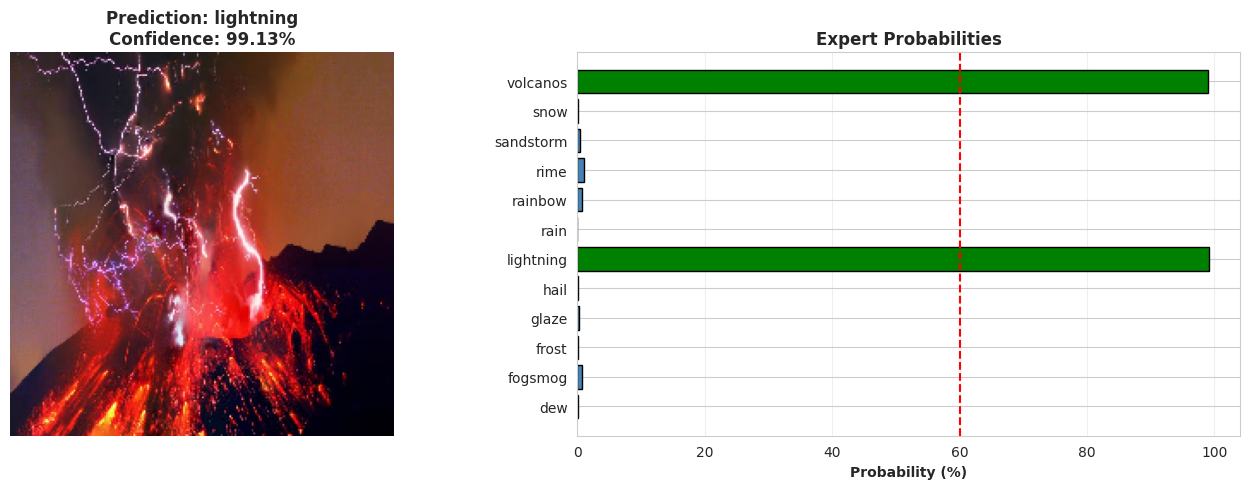


TOP 3 PREDICTIONS
1. lightning      : 99.13%
2. volcanos       : 98.94%
3. rime           : 1.04%
Active labels (thr=0.60): lightning, volcanos


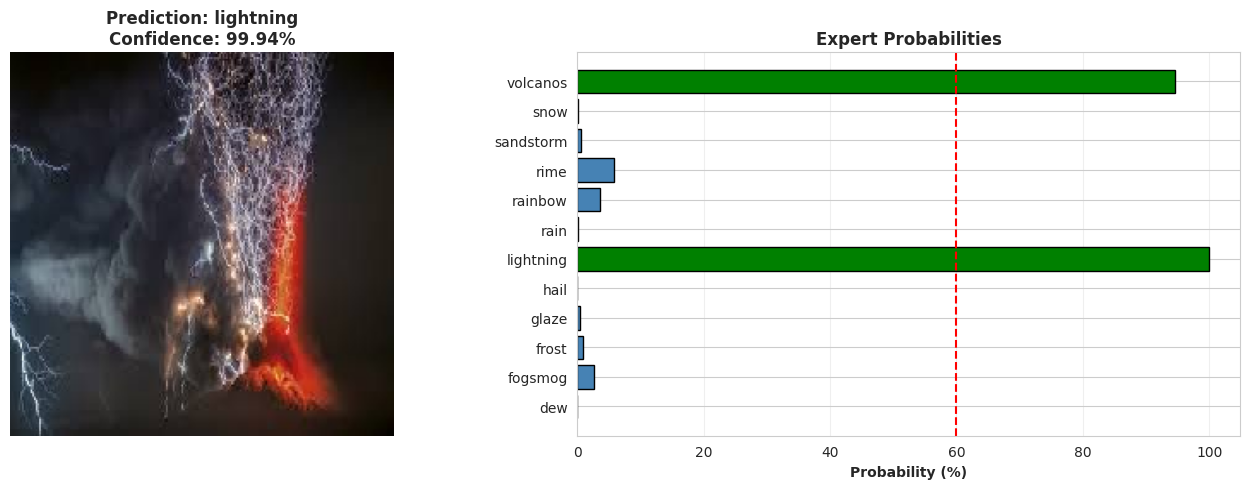


TOP 3 PREDICTIONS
1. lightning      : 99.94%
2. volcanos       : 94.62%
3. rime           : 5.77%
Active labels (thr=0.60): lightning, volcanos


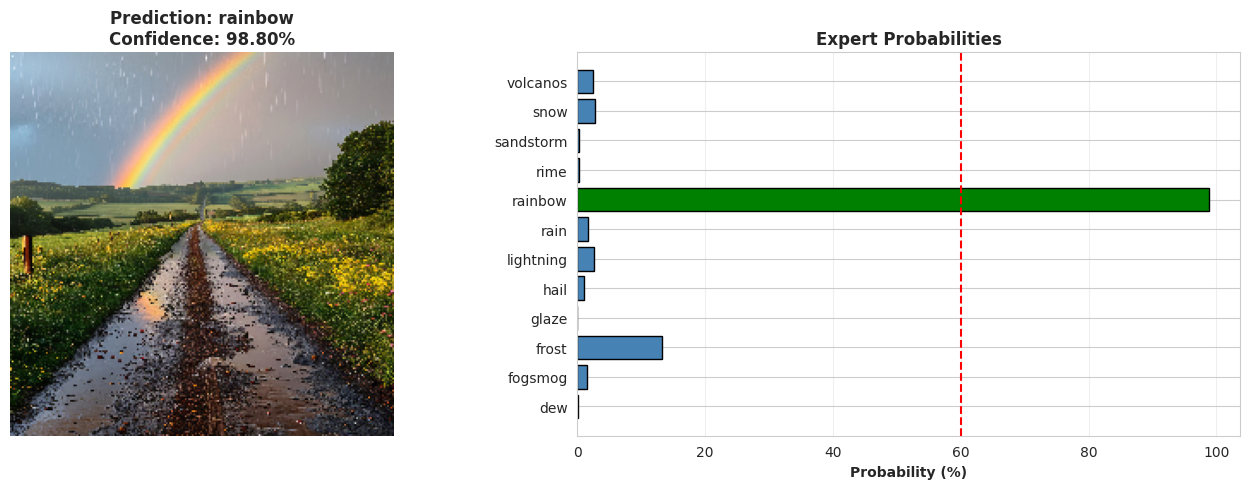


TOP 3 PREDICTIONS
1. rainbow        : 98.80%
2. frost          : 13.18%
3. snow           : 2.70%
Active labels (thr=0.60): rainbow


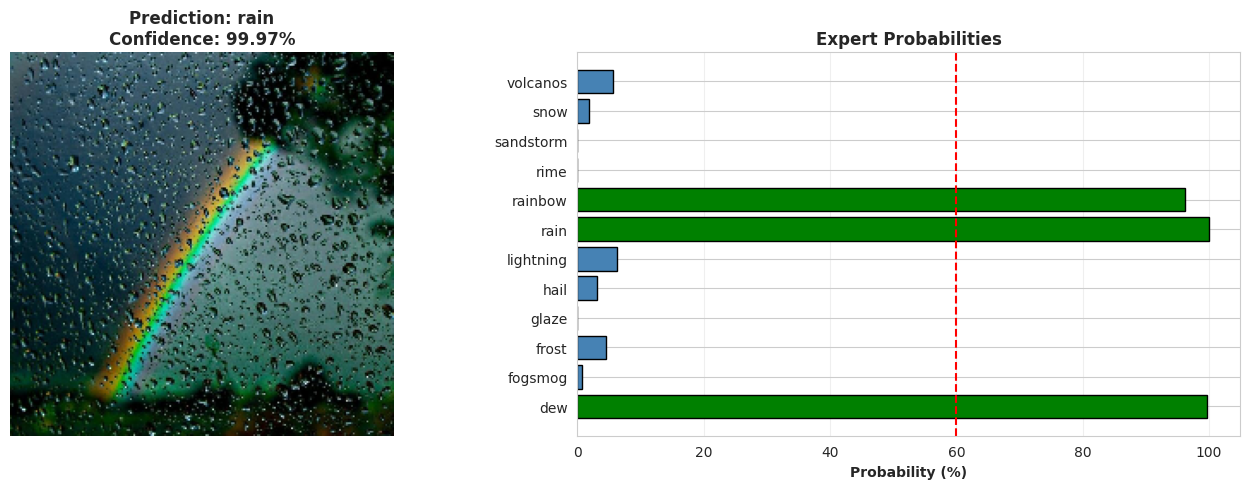


TOP 3 PREDICTIONS
1. rain           : 99.97%
2. dew            : 99.77%
3. rainbow        : 96.22%
Active labels (thr=0.60): dew, rain, rainbow


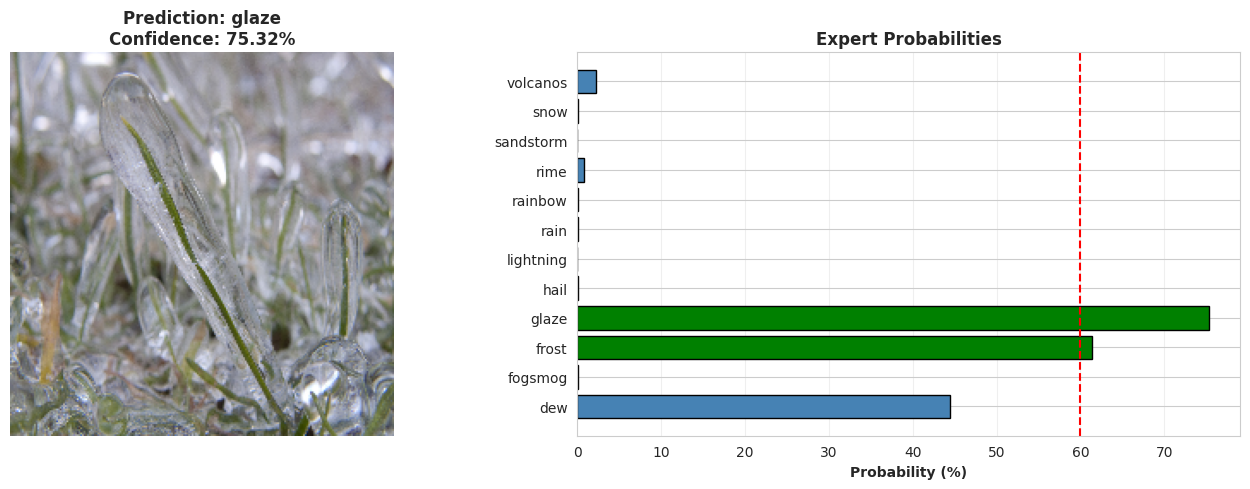


TOP 3 PREDICTIONS
1. glaze          : 75.32%
2. frost          : 61.37%
3. dew            : 44.46%
Active labels (thr=0.60): frost, glaze


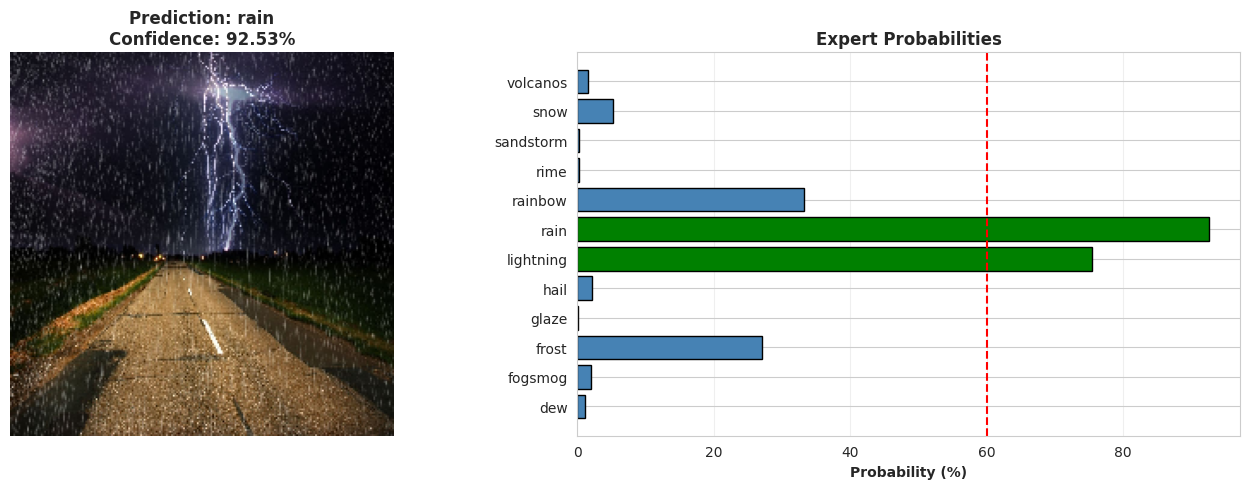


TOP 3 PREDICTIONS
1. rain           : 92.53%
2. lightning      : 75.37%
3. rainbow        : 33.17%
Active labels (thr=0.60): lightning, rain


[{'image': 'volcano_lightning.jpeg', 'active': 'lightning,volcanos'},
 {'image': 'volcano_lightning_2.jpg', 'active': 'lightning,volcanos'},
 {'image': 'rainbow-rain.jpg', 'active': 'rainbow'},
 {'image': 'rainbow-rain-2.jpg', 'active': 'dew,rain,rainbow'},
 {'image': 'glaze.jpg', 'active': 'frost,glaze'},
 {'image': 'rain-lightning.jpg', 'active': 'lightning,rain'}]

In [14]:
example_images = [
f'{MAIN_PATH}/predict/volcano_lightning.jpeg',
f'{MAIN_PATH}/predict/volcano_lightning_2.jpg',
f'{MAIN_PATH}/predict/rainbow-rain.jpg',
f'{MAIN_PATH}/predict/rainbow-rain-2.jpg',
f'{MAIN_PATH}/predict/glaze.jpg',
f'{MAIN_PATH}/predict/rain-lightning.jpg'
]
print("Running Binary Relevance predictions on example images...")
predict_multiple_br(example_images, threshold=THRESHOLD)